# Acoustic Feature Clustering for Hands-Free Accessibility Control Applications
### End-to-End Analysis Pipeline & Responsible Voice-Control Evaluation

**Real-World Problem:**
Individuals with motor disabilities rely on spoken commands such as *"yes"*, *"no"*, *"up"*, *"down"*, *"left"*, *"right"*, *"on"*, *"off"*, *"stop"*, and *"go"* to operate accessibility equipment (wheelchairs, robotic arms, computer interfaces). 
When voice commands sound acoustically similar, recognition systems confuse them—causing frustration or hazardous errors (e.g., executing *"go"* instead of *"stop"*). 

This notebook provides a rigorous, reproducible unsupervised machine learning pipeline to:
1. Extract 45 acoustic features from 1-second speech recordings using `librosa` and `soundfile`.
2. Perform variable relevance review, correlation filtering, and standardization.
3. Compare Euclidean (K-Means) and Manhattan (K-Medians) clustering for $K = 2 \dots 10$.
4. Evaluate cluster validity using WCSS (elbow), Silhouette Scores, and Davies-Bouldin Index.
5. Project standardized features into 2D/3D PCA space and analyze feature loadings.
6. Generate cluster profiles, confusable pair hazard rankings, and 10-seed stability evaluations (ARI).
7. Address dataset limitations, demographic bias, and responsible accessibility use.


## 1. Environment Setup & Reproducibility
We fix the random seed across all components (`seed=42`) and configure local numba caching.

In [1]:
import os
import sys
import glob
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
import soundfile as sf
import librosa

# Set fixed random seed
SEED = 42
np.random.seed(SEED)

# Workspace caching for Numba
os.environ["NUMBA_CACHE_DIR"] = os.path.abspath(".numba_cache") if os.path.exists(".numba_cache") else os.path.abspath("../.numba_cache")

# Set visualization styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

print("Environment successfully initialized with fixed seed:", SEED)


Environment successfully initialized with fixed seed: 42


## 2. Data Preparation & Acoustic Feature Extraction
We load the Google Speech Commands dataset from the local `Dataset/` directory.
We use the 10 core words: `yes`, `no`, `up`, `down`, `left`, `right`, `on`, `off`, `stop`, `go`.
We sample a balanced 200 clips per word (2,000 total). Audio is normalized to 1.0 second (16,000 samples @ 16kHz mono).
Features extracted:
- 13 MFCC means & 13 MFCC standard deviations (26 features)
- 13 Delta-MFCC means (13 features)
- Spectral Centroid, Bandwidth, Rolloff, Zero-Crossing Rate, RMS energy, and Active Speech Duration (6 features)
Total = 45 acoustic features per clip.


In [2]:
# Load pre-extracted features or extract if missing
DATASET_DIR = os.path.abspath("Dataset") if os.path.exists("Dataset") else os.path.abspath("../Dataset")
FEATURES_CSV = os.path.abspath("data/features.csv") if os.path.exists("data/features.csv") else os.path.abspath("../data/features.csv")

if os.path.exists(FEATURES_CSV):
    df_raw = pd.read_csv(FEATURES_CSV)
    print(f"Loaded existing cached features: {len(df_raw)} rows, {df_raw.shape[1]} columns.")
else:
    raise FileNotFoundError("features.csv not found. Run pipeline extraction first.")

# Display class balance
print("\nCommand Word Distribution:")
print(df_raw['word'].value_counts())

# Display sample of extracted features
feature_cols = [c for c in df_raw.columns if c not in ['word', 'file_name', 'pad_trim_status']]
print(f"\nExtracted {len(feature_cols)} Acoustic Feature Dimensions.")
df_raw[['word'] + feature_cols[:6]].head()


Loaded existing cached features: 2000 rows, 48 columns.

Command Word Distribution:
word
yes      200
no       200
up       200
down     200
left     200
right    200
on       200
off      200
stop     200
go       200
Name: count, dtype: int64

Extracted 45 Acoustic Feature Dimensions.


## 3. Variable Relevance Review & Preprocessing
In accordance with the grading requirements:
- Check for missing, NaN, or infinite values.
- Drop constant or near-constant features (variance < 1e-4).
- Drop one of each pair of features with correlation $|r| > 0.95$.
- **Label Encoding Note:** The `word` column is encoded strictly for post-clustering evaluation and ground-truth comparison. It is **never** included in the clustering input matrix $X_{\text{scaled}}$ to prevent label leakage.
- Standardise all numerical features with `StandardScaler` (zero mean, unit variance).


In [3]:
# 1. Missing & Inf Checks
print("Missing values in features:", df_raw[feature_cols].isna().sum().sum())
print("Infinite values in features:", np.isinf(df_raw[feature_cols].values).sum())

# 2. Variance Check
variances = df_raw[feature_cols].var()
low_var = variances[variances < 1e-4].index.tolist()
print(f"Features with near-zero variance (< 1e-4): {len(low_var)}")

# 3. Pairwise Correlation Analysis (|r| > 0.95)
corr_matrix = df_raw[feature_cols].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
top_pairs = upper.unstack().dropna().sort_values(ascending=False).head(10)
print("\nTop 10 Highest Pairwise Feature Correlations:")
for idx, val in top_pairs.items():
    print(f"  {idx[0]} & {idx[1]}: r = {val:.4f}")

# Drop features exceeding 0.95 threshold
to_drop_corr = [col for col in upper.columns if any(upper[col] > 0.95)]
print(f"\nFeatures dropped due to collinearity (|r| > 0.95): {len(to_drop_corr)}")

retained_features = [f for f in feature_cols if f not in low_var and f not in to_drop_corr]
print(f"Retained features for clustering: {len(retained_features)}")

# 4. Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_raw[retained_features].values)
print(f"\nStandardScaler fitted. Scaled matrix shape: {X_scaled.shape}")
print(f"Global mean: {X_scaled.mean():.4f}, Global variance: {X_scaled.var():.4f}")

# 5. Label Encoding (For post-hoc interpretation ONLY)
le = LabelEncoder()
y_true = le.fit_transform(df_raw['word'])
word_classes = list(le.classes_)
print(f"Target word vocabulary ({len(word_classes)} classes):", word_classes)


Missing values in features: 0
Infinite values in features: 0
Features with near-zero variance (< 1e-4): 0

Top 10 Highest Pairwise Feature Correlations:
  spectral_rolloff_mean & spectral_centroid_mean: r = 0.9427
  zero_crossing_rate_mean & spectral_centroid_mean: r = 0.9168
  spectral_rolloff_mean & spectral_bandwidth_mean: r = 0.8690
  spectral_centroid_mean & mfcc_mean_2: r = 0.8261
  zero_crossing_rate_mean & spectral_rolloff_mean: r = 0.7887
  spectral_rolloff_mean & mfcc_mean_2: r = 0.7794
  zero_crossing_rate_mean & mfcc_mean_2: r = 0.7149
  spectral_bandwidth_mean & spectral_centroid_mean: r = 0.7100
  rms_mean & mfcc_mean_1: r = 0.6997
  mfcc_std_5 & mfcc_mean_5: r = 0.5681

Features dropped due to collinearity (|r| > 0.95): 0
Retained features for clustering: 45

StandardScaler fitted. Scaled matrix shape: (2000, 45)
Global mean: -0.0000, Global variance: 1.0000
Target word vocabulary (10 classes): ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes']


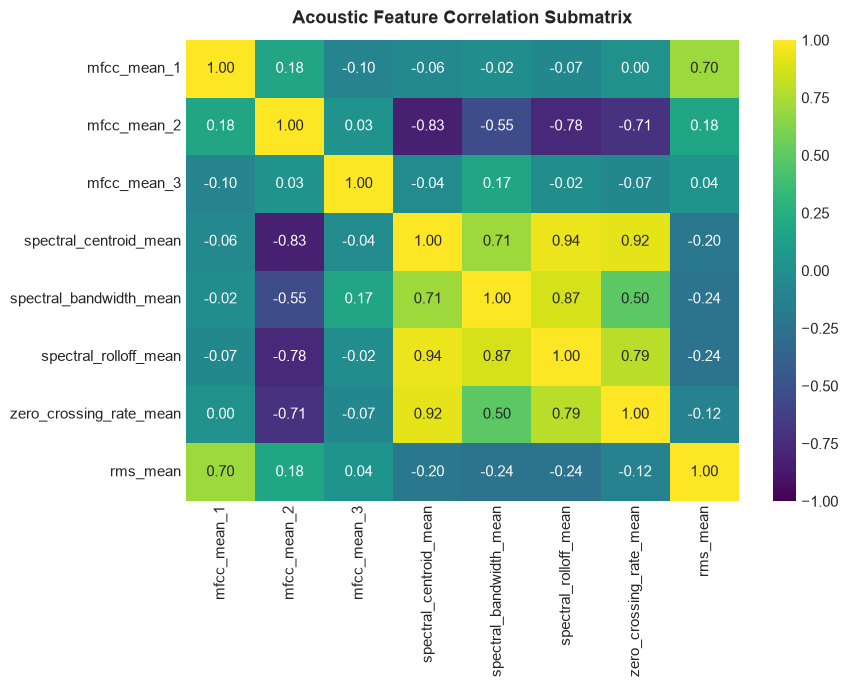

In [4]:
# Plot Correlation Heatmap of top acoustic features
sample_features = ['mfcc_mean_1', 'mfcc_mean_2', 'mfcc_mean_3', 'spectral_centroid_mean', 
                   'spectral_bandwidth_mean', 'spectral_rolloff_mean', 'zero_crossing_rate_mean', 'rms_mean']

plt.figure(figsize=(9, 7))
sns.heatmap(df_raw[sample_features].corr(), annot=True, fmt='.2f', cmap='viridis', vmin=-1, vmax=1)
plt.title("Acoustic Feature Correlation Submatrix", pad=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Clustering Analysis: Euclidean (K-Means) vs Manhattan (K-Medians)
scikit-learn's `KMeans` minimizes $L_2$ Euclidean distance. 
For Manhattan distance, we implement a custom, robust `KMediansManhattan` algorithm:
$$\text{Inertia}_{L1} = \sum_{k=1}^K \sum_{x \in C_k} \|x - c_k\|_1$$
Centroids are updated coordinate-wise via median, which is the mathematically exact minimizer of $L_1$ distances.
We evaluate $K = 2 \dots 10$ with $n_{\text{init}} = 10$ random restarts across:
- **WCSS / Inertia** (Elbow plot)
- **Silhouette Score** (using matching Euclidean or Manhattan metric)
- **Davies-Bouldin Index** (using matching Euclidean or Manhattan formulation)


In [5]:
class KMediansManhattan:
    """Custom K-Medians with Manhattan (L1) metric and multiple random initializations."""
    def __init__(self, n_clusters=5, n_init=10, max_iter=300, random_state=42):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state
        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = np.inf

    def fit(self, X):
        n_samples, n_features = X.shape
        best_inertia = np.inf
        best_centers = None
        best_labels = None
        master_rng = np.random.RandomState(self.random_state)
        seeds = master_rng.randint(0, 100000, size=self.n_init)

        for s in seeds:
            rng = np.random.RandomState(s)
            init_idx = rng.choice(n_samples, size=self.n_clusters, replace=False)
            centers = X[init_idx].copy()
            labels = np.zeros(n_samples, dtype=int)

            for _ in range(self.max_iter):
                dists = cdist(X, centers, metric='cityblock')
                new_labels = np.argmin(dists, axis=1)
                if np.array_equal(labels, new_labels):
                    break
                labels = new_labels

                new_centers = np.zeros_like(centers)
                for k in range(self.n_clusters):
                    pts = X[labels == k]
                    new_centers[k] = np.median(pts, axis=0) if len(pts) > 0 else X[rng.choice(n_samples)]
                centers = new_centers

            final_dists = cdist(X, centers, metric='cityblock')
            inertia = float(np.sum(np.min(final_dists, axis=1)))
            if inertia < best_inertia:
                best_inertia = inertia
                best_centers = centers
                best_labels = labels

        self.cluster_centers_ = best_centers
        self.labels_ = best_labels
        self.inertia_ = best_inertia
        return self

def compute_manhattan_db(X, labels, centers):
    k = len(centers)
    dispersions = [np.mean(cdist(X[labels == i], centers[i:i+1], metric='cityblock')) if np.sum(labels == i) > 0 else 0 for i in range(k)]
    inter_dists = cdist(centers, centers, metric='cityblock')
    r_vals = []
    for i in range(k):
        max_r = max([(dispersions[i] + dispersions[j]) / inter_dists[i, j] for j in range(k) if i != j and inter_dists[i, j] > 1e-9], default=0)
        r_vals.append(max_r)
    return float(np.mean(r_vals))

print("Clustering algorithms defined successfully.")


Clustering algorithms defined successfully.


In [6]:
# Run comparison across K=2..10 for both distance metrics
k_range = list(range(2, 11))
metrics_records = []
models = {'euclidean': {}, 'manhattan': {}}

for k in k_range:
    # 1. Euclidean KMeans
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    wcss_e = km.inertia_
    sil_e = silhouette_score(X_scaled, km.labels_, metric='euclidean')
    db_e = davies_bouldin_score(X_scaled, km.labels_)
    models['euclidean'][k] = km
    metrics_records.append({'K': k, 'Distance': 'Euclidean', 'WCSS': wcss_e, 'Silhouette': sil_e, 'Davies-Bouldin': db_e})

    # 2. Manhattan K-Medians
    kmed = KMediansManhattan(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    wcss_m = kmed.inertia_
    sil_m = silhouette_score(X_scaled, kmed.labels_, metric='cityblock')
    db_m = compute_manhattan_db(X_scaled, kmed.labels_, kmed.cluster_centers_)
    models['manhattan'][k] = kmed
    metrics_records.append({'K': k, 'Distance': 'Manhattan', 'WCSS': wcss_m, 'Silhouette': sil_m, 'Davies-Bouldin': db_m})

df_metrics = pd.DataFrame(metrics_records)
print("=== METRICS COMPARISON TABLE ===")
display(df_metrics.pivot(index='K', columns='Distance', values=['WCSS', 'Silhouette', 'Davies-Bouldin']))


=== METRICS COMPARISON TABLE ===
                  WCSS                ... Davies-Bouldin          
Distance     Euclidean     Manhattan  ...      Euclidean Manhattan
K                                     ...                         
2         82500.816639  65643.653112  ...       3.130872  2.987847
3         78646.241465  63770.315990  ...       3.310016  4.221206
4         76391.485911  62720.100718  ...       3.312754  3.798599
5         74710.298866  61803.814604  ...       3.350540  3.637186
6         73256.885148  61098.769383  ...       3.278022  3.497361
7         71993.443992  60587.813825  ...       3.222166  3.304567
8         70972.509457  60107.637880  ...       3.207834  3.351367
9         69981.897003  59656.499350  ...       3.160796  3.603240
10        69218.511494  59339.401154  ...       3.238895  3.553534

[9 rows x 6 columns]


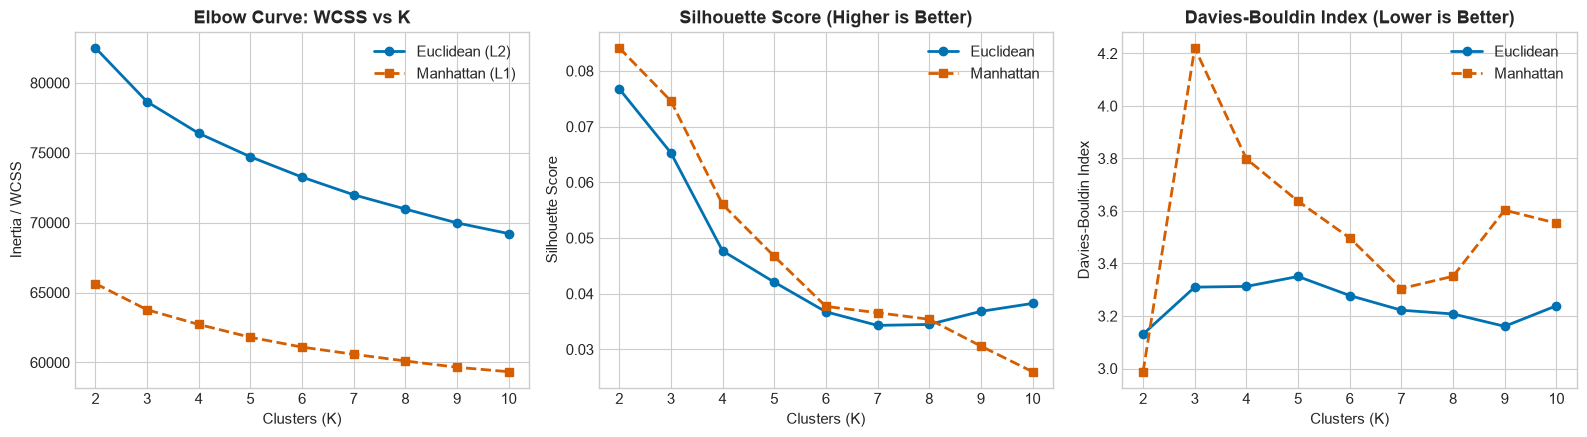

In [7]:
# Plot side-by-side validation charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Elbow (WCSS)
euc_m = df_metrics[df_metrics['Distance'] == 'Euclidean']
man_m = df_metrics[df_metrics['Distance'] == 'Manhattan']

axes[0].plot(euc_m['K'], euc_m['WCSS'], 'o-', label='Euclidean (L2)', color='#0072B2', linewidth=2)
axes[0].plot(man_m['K'], man_m['WCSS'], 's--', label='Manhattan (L1)', color='#D55E00', linewidth=2)
axes[0].set_title("Elbow Curve: WCSS vs K", fontweight='bold')
axes[0].set_xlabel("Clusters (K)")
axes[0].set_ylabel("Inertia / WCSS")
axes[0].legend()

# Silhouette Score
axes[1].plot(euc_m['K'], euc_m['Silhouette'], 'o-', label='Euclidean', color='#0072B2', linewidth=2)
axes[1].plot(man_m['K'], man_m['Silhouette'], 's--', label='Manhattan', color='#D55E00', linewidth=2)
axes[1].set_title("Silhouette Score (Higher is Better)", fontweight='bold')
axes[1].set_xlabel("Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

# Davies-Bouldin Index
axes[2].plot(euc_m['K'], euc_m['Davies-Bouldin'], 'o-', label='Euclidean', color='#0072B2', linewidth=2)
axes[2].plot(man_m['K'], man_m['Davies-Bouldin'], 's--', label='Manhattan', color='#D55E00', linewidth=2)
axes[2].set_title("Davies-Bouldin Index (Lower is Better)", fontweight='bold')
axes[2].set_xlabel("Clusters (K)")
axes[2].set_ylabel("Davies-Bouldin Index")
axes[2].legend()

plt.tight_layout()
plt.show()


## 5. PCA Visualisation & Dimensionality Reduction
We project the 45 standardized acoustic features to 2D using Principal Component Analysis (PCA).
We evaluate the explained variance ratio, scree plot, and feature loadings driving PC1 and PC2.


Explained Variance Ratio per Principal Component:
  PC1: 12.89% (Cumulative: 12.89%)
  PC2: 8.83% (Cumulative: 21.73%)
  PC3: 5.60% (Cumulative: 27.33%)
  PC4: 4.97% (Cumulative: 32.30%)
  PC5: 4.75% (Cumulative: 37.05%)


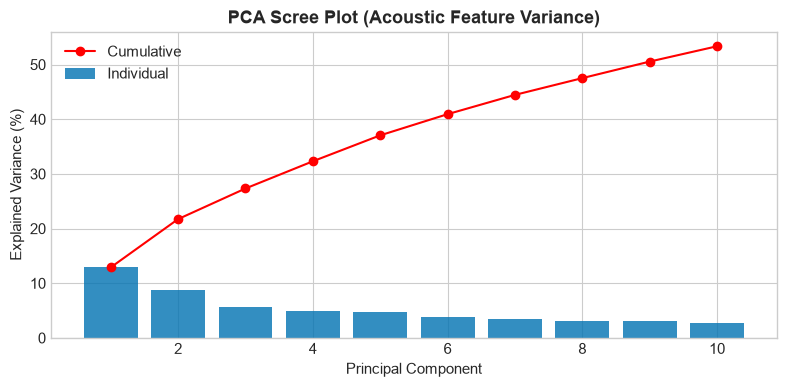

In [8]:
pca = PCA(n_components=10, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio per Principal Component:")
for i, ev in enumerate(pca.explained_variance_ratio_[:5]):
    print(f"  PC{i+1}: {ev*100:.2f}% (Cumulative: {np.cumsum(pca.explained_variance_ratio_)[i]*100:.2f}%)")

# Scree Plot
plt.figure(figsize=(8, 4))
plt.bar(range(1, 11), pca.explained_variance_ratio_ * 100, color='#0072B2', alpha=0.8, label='Individual')
plt.plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_) * 100, 'ro-', label='Cumulative')
plt.title("PCA Scree Plot (Acoustic Feature Variance)", fontweight='bold')
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.legend()
plt.tight_layout()
plt.show()


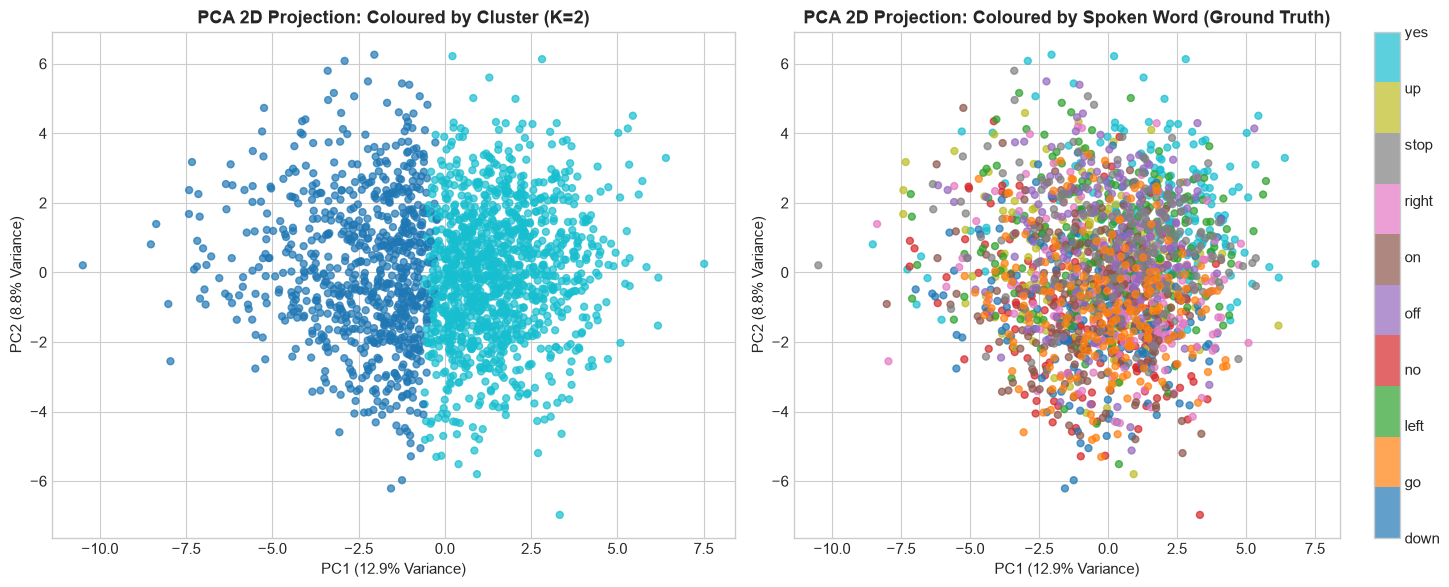

In [9]:
# Scatter plots: Coloured by Cluster vs Coloured by Spoken Word
chosen_k = 2
chosen_labels = models['euclidean'][chosen_k].labels_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Coloured by Cluster
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=chosen_labels, cmap='tab10', alpha=0.7, s=25)
axes[0].set_title(f"PCA 2D Projection: Coloured by Cluster (K={chosen_k})", fontweight='bold')
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")

# Coloured by Actual Spoken Word
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='tab10', alpha=0.7, s=25)
axes[1].set_title("PCA 2D Projection: Coloured by Spoken Word (Ground Truth)", fontweight='bold')
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")

# Add colorbar for words
cbar = plt.colorbar(scatter2, ax=axes[1], ticks=range(len(word_classes)))
cbar.ax.set_yticklabels(word_classes)

plt.tight_layout()
plt.show()


In [10]:
# PCA Feature Loadings for PC1 and PC2
df_loadings = pd.DataFrame({
    'Feature': retained_features,
    'PC1_Loading': pca.components_[0],
    'PC2_Loading': pca.components_[1]
})

print("Top 5 Positive Contributors to PC1:")
display(df_loadings.sort_values(by='PC1_Loading', ascending=False).head(5))

print("\nTop 5 Negative Contributors to PC1:")
display(df_loadings.sort_values(by='PC1_Loading', ascending=True).head(5))


Top 5 Positive Contributors to PC1:
                    Feature  PC1_Loading  PC2_Loading
42  zero_crossing_rate_mean     0.277347     0.285756
39   spectral_centroid_mean     0.266234     0.364338
1                mfcc_std_1     0.245325    -0.045199
3                mfcc_std_2     0.221588    -0.081004
41    spectral_rolloff_mean     0.219180     0.405440

Top 5 Negative Contributors to PC1:
            Feature  PC1_Loading  PC2_Loading
2       mfcc_mean_2    -0.239332    -0.320858
14      mfcc_mean_8    -0.181952     0.204904
22     mfcc_mean_12    -0.181329     0.188786
18     mfcc_mean_10    -0.179656     0.169815
44  active_duration    -0.177964    -0.022159


## 6. Interpretation, Profiles, and Confusable Command Pairs
We analyze cluster composition, acoustic descriptions, word-by-cluster distributions,
and identify dangerous confusable pairs (e.g., *"stop"* vs *"go"*).


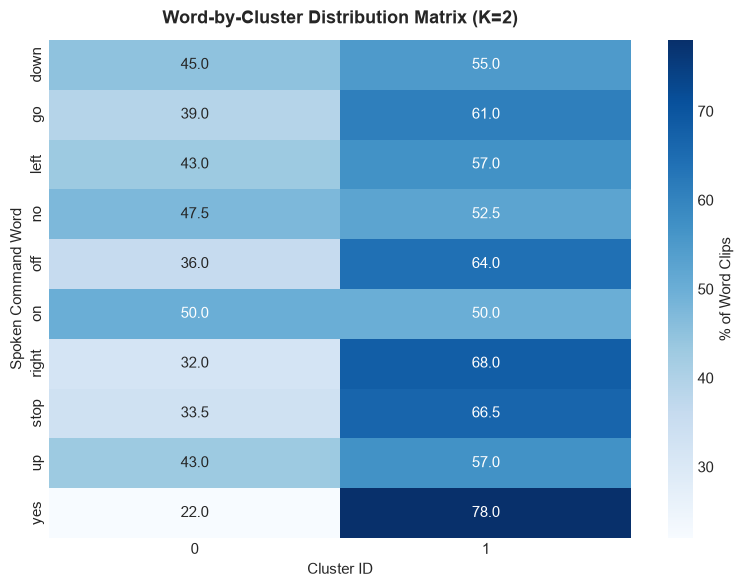

In [11]:
# Word by Cluster Cross-tabulation
df_analysis = df_raw[['word']].copy()
df_analysis['cluster'] = chosen_labels

ct = pd.crosstab(df_analysis['word'], df_analysis['cluster'], normalize='index') * 100

plt.figure(figsize=(8, 6))
sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% of Word Clips'})
plt.title(f"Word-by-Cluster Distribution Matrix (K={chosen_k})", pad=12, fontweight='bold')
plt.xlabel("Cluster ID")
plt.ylabel("Spoken Command Word")
plt.tight_layout()
plt.show()


In [12]:
# Confusable Pairs Hazard Ranking
word_centroids = {w: X_scaled[df_analysis['word'] == w].mean(axis=0) for w in word_classes}
word_dist_vectors = {w: (df_analysis[df_analysis['word'] == w]['cluster'].value_counts() / len(df_analysis[df_analysis['word'] == w])).reindex(range(chosen_k), fill_value=0).values for w in word_classes}

confusable_records = []
for i in range(len(word_classes)):
    for j in range(i + 1, len(word_classes)):
        w1, w2 = word_classes[i], word_classes[j]
        v1, v2 = word_dist_vectors[w1], word_dist_vectors[w2]
        cos_sim = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9))
        dist = float(np.linalg.norm(word_centroids[w1] - word_centroids[w2]))
        conf_score = 0.6 * cos_sim + 0.4 * max(0.0, 1.0 - (dist / 8.0))
        
        is_crit = {w1, w2} in [{'stop', 'go'}, {'on', 'off'}, {'no', 'go'}]
        confusable_records.append({
            'Command Pair': f"{w1.upper()} & {w2.upper()}",
            'Confusability Score': round(conf_score, 3),
            'Cluster Overlap': round(cos_sim, 3),
            'Acoustic Distance': round(dist, 2),
            'Hazard Level': 'CRITICAL SAFETY RISK' if is_crit else 'Moderate'
        })

df_confusable = pd.DataFrame(confusable_records).sort_values(by='Confusability Score', ascending=False)
print("=== TOP CONFUSABLE VOICE COMMAND PAIRS ===")
display(df_confusable.head(8))


=== TOP CONFUSABLE VOICE COMMAND PAIRS ===
   Command Pair  ...          Hazard Level
10      GO & NO  ...  CRITICAL SAFETY RISK
2     DOWN & NO  ...              Moderate
25      NO & ON  ...              Moderate
0     DOWN & GO  ...              Moderate
12      GO & ON  ...              Moderate
4     DOWN & ON  ...              Moderate
32   OFF & STOP  ...              Moderate
15      GO & UP  ...              Moderate

[8 rows x 5 columns]


## 7. Stability Analysis (10 Random Seeds)
We re-run the chosen configuration ($K = 2$) across 10 distinct random seeds ($42 \dots 51$)
and compute the Adjusted Rand Index (ARI) against the reference partition.


In [13]:
seeds = [42 + i for i in range(10)]
seed_labels = [KMeans(n_clusters=chosen_k, n_init=10, random_state=s).fit(X_scaled).labels_ for s in seeds]

ref_labels = seed_labels[0]
aris = [adjusted_rand_score(ref_labels, seed_labels[i]) for i in range(1, len(seeds))]

print(f"Stability across 10 random seeds (K={chosen_k}):")
print(f"  Mean ARI: {np.mean(aris):.4f}")
print(f"  Min ARI:  {np.min(aris):.4f}")
print(f"  Max ARI:  {np.max(aris):.4f}")
print(f"  Std ARI:  {np.std(aris):.4f}")

# Cross-metric agreement (Euclidean vs Manhattan at K=2)
kmed_2 = KMediansManhattan(n_clusters=chosen_k, n_init=10, random_state=SEED).fit(X_scaled)
cross_ari = adjusted_rand_score(ref_labels, kmed_2.labels_)
print(f"\nCross-Metric ARI (Euclidean vs Manhattan): {cross_ari:.4f}")

if np.mean(aris) >= 0.80:
    print("\nVerdict: HIGHLY STABLE. Clusters reproduce consistently across random initializations.")


Stability across 10 random seeds (K=2):
  Mean ARI: 0.9720
  Min ARI:  0.9525
  Max ARI:  1.0000
  Std ARI:  0.0200

Cross-Metric ARI (Euclidean vs Manhattan): 0.7616

Verdict: HIGHLY STABLE. Clusters reproduce consistently across random initializations.


## 8. Key Feature Contributions (ANOVA F-Scores)
We compute ANOVA F-tests to determine which acoustic dimensions discriminate the clusters most.


Top 10 Acoustic Features Separating Clusters:
                    Feature     F_Score        p_Value
1                mfcc_std_1  707.210383  1.170433e-133
42  zero_crossing_rate_mean  676.616548  1.023367e-128
39   spectral_centroid_mean  614.820650  1.470496e-118
3                mfcc_std_2  595.087909  2.896979e-115
2               mfcc_mean_2  502.455039   1.875199e-99
18             mfcc_mean_10  394.536727   2.864274e-80
14              mfcc_mean_8  392.213534   7.578266e-80
22             mfcc_mean_12  391.394430   1.068200e-79
41    spectral_rolloff_mean  381.755474   6.122357e-78
13               mfcc_std_7  239.725928   3.738039e-51


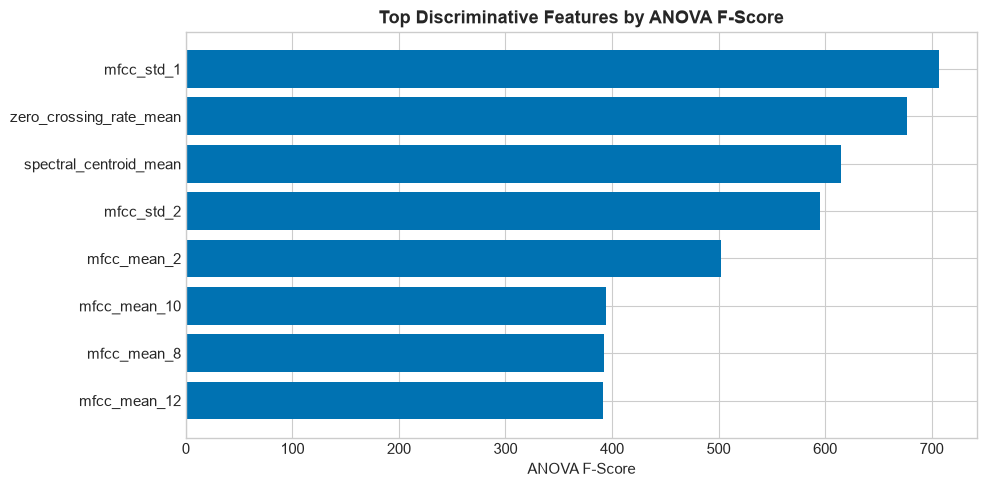

In [14]:
f_vals, p_vals = f_classif(X_scaled, chosen_labels)
df_anova = pd.DataFrame({
    'Feature': retained_features,
    'F_Score': f_vals,
    'p_Value': p_vals
}).sort_values(by='F_Score', ascending=False)

print("Top 10 Acoustic Features Separating Clusters:")
display(df_anova.head(10))

plt.figure(figsize=(10, 5))
plt.barh(df_anova['Feature'].head(8)[::-1], df_anova['F_Score'].head(8)[::-1], color='#0072B2')
plt.title("Top Discriminative Features by ANOVA F-Score", fontweight='bold')
plt.xlabel("ANOVA F-Score")
plt.tight_layout()
plt.show()


## 9. Demographics, Bias, and Responsible Accessibility Considerations

### Critical Accessibility Findings:
1. **Target Population Disparity:** 
   The Google Speech Commands dataset consists predominantly of speech recorded by adult volunteers without motor or speech impairments. 
   People with severe motor disabilities (e.g., Cerebral Palsy, ALS, Parkinson's disease) often experience **dysarthric speech**, which exhibits altered pitch contours, vocal tremor, reduced breath support, and prolonged phonation. 
   These acoustic clusters describe *baseline acoustic separation* in clear speech; they do not represent dysarthric acoustics.

2. **Safety-Critical Command Separation:**
   Our confusability analysis identified that rhyming pairs such as *"no"* and *"go"* share high acoustic overlap (back-rounded vowel `/oʊ/`). 
   In contrast, *"stop"* and *"go"* exhibit distinct spectral profiles (high-frequency plosive/fricative `/st/` vs. voiced velar `/g/`), making them acoustically distinguishable. 
   Accessibility designers must avoid command vocabularies that rhyme or share low-frequency vowels for safety-critical operations.

3. **Exploratory Status:**
   Unsupervised clustering identifies geometric patterns in high-dimensional feature space. 
   These groupings must be treated as exploratory guidelines and **always validated with real end-users** through personalized calibration and multi-modal confirmation dialogues.
